In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Library

In [6]:
import pandas as pd
import numpy as np
import os
import json
import time

import matplotlib.pyplot as plt
import seaborn as sns

# Clothing Shoes

In [5]:
df = pd.read_pickle('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Clothing_Shoes_v5_final.pkl')

print(df.shape)
df.head()

(66718, 17)


,user_id,asin,parent_asin,text,rating,title_y,roberta_emb,small_image_url,medium_image_url,large_image_url,VGG16_emb,user_bert_emb,item_bert_emb,user_roberta_emb,item_roberta_emb,LLaMA_Output,LLaVA_Output
0,AFJBKPK5W56XWSNPQU2WW66ISWYQ,B08HQPWVCC,B08HQPWVCC,Pretty colored earrings but color of stainless...,4,Udalyn 6pairs Stud Earrings Set for Women Opal...,"[-0.08417237550000001, 0.1606151462, -0.014070...",https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,"[0.0, 12.1029911041, 0.0, 15.7332105637, 4.268...","[-0.5218123, -0.96434146, 0.4619303, -0.409749...","[-0.20688048, -0.32638466, 0.13180715, -0.5702...","[-0.110578634, 0.11269227, -0.041261047, -0.10...","[-0.06857138, 0.13921358, -0.039587017, -0.088...","Based on user reviews, it appears that users a...",The image shows a hand holding a set of earrin...
1,AFJBKPK5W56XWSNPQU2WW66ISWYQ,B08JQ88186,B08JQ88186,Great little earrings. Perfect size. Not too b...,5,ZENI 925 Sterling Silver Snowflake Earrings fo...,"[-0.0825007036, 0.175420925, -0.054644376, -0....",https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,"[0.0, 0.0, 2.2863385677, 10.4048433304, 6.9813...","[-0.5218123, -0.96434146, 0.4619303, -0.409749...","[0.062450625, -0.07075825, 0.15572476, -0.2797...","[-0.110578634, 0.11269227, -0.041261047, -0.10...","[-0.04617965, 0.12618569, -0.017711096, -0.102...","Based on user reviews, it appears that users p...",The image shows a close-up of a person's ear w...
2,AFJBKPK5W56XWSNPQU2WW66ISWYQ,B07YXXR1DG,B07YXXR1DG,Great bracelet key chain. Perfect for busy mom...,5,Bangle key ring Bracelet Keychain wristlet key...,"[-0.09092549230000001, 0.1620114595, -0.038774...",https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,"[0.0, 37.5705032349, 2.7596354485, 0.0, 12.911...","[-0.5218123, -0.96434146, 0.4619303, -0.409749...","[-0.26902932, -0.42407188, 0.82339007, -0.2940...","[-0.110578634, 0.11269227, -0.041261047, -0.10...","[-0.062135138, 0.1333665, -0.019405615, -0.102...","Based on this review, it seems that users pref...","The image shows a fashion accessory, specifica..."
3,AFJBKPK5W56XWSNPQU2WW66ISWYQ,B07RHSJQQN,B07RHSJQQN,This is a nice patriotic tank. The medium fits...,4,YEXIPO Womens American Flag Racerback Tank Top...,"[-0.12041848150000001, 0.0892145857, -0.027717...",https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,"[0.0, 18.6175479889, 0.0, 0.0, 3.5440309048, 0...","[-0.5218123, -0.96434146, 0.4619303, -0.409749...","[0.119323395, -0.57359934, 0.40760195, -0.2408...","[-0.110578634, 0.11269227, -0.041261047, -0.10...","[-0.06780286, 0.051634714, -0.017799914, -0.11...","Based on user reviews, it appears that users p...",The image shows a sleeveless tank top with a p...
4,AFJBKPK5W56XWSNPQU2WW66ISWYQ,B07LFZRYC2,B07LFZRYC2,Great boys shirt. My grandson wears a medium i...,5,Hurley Boys' One and Ony Graphic T-Shirt,"[-0.1369395405, 0.07035727800000001, -0.060328...",https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,"[1.9380488396, 0.0, 0.0, 6.4230856895, 0.0, 0....","[-0.5218123, -0.96434146, 0.4619303, -0.409749...","[-0.43734312, -0.62041384, 0.14694075, -0.3723...","[-0.110578634, 0.11269227, -0.041261047, -0.10...","[-0.07941287, 0.05176169, -0.02554227, -0.0903...","Based on the user review, it appears that the ...",The image shows a lime green t-shirt with a gr...


In [27]:
# 데이터셋에서 글자 수 확인
text_length = df['text'].apply(lambda row : len(row)).describe(percentiles=[0.10, 0.25, 0.5, 0.75, 0.9, 0.95]).astype(int)

text_length

,text
count,66718
mean,475
std,425
min,4
10%,129
25%,213
50%,361
75%,599
90%,939
95%,1233


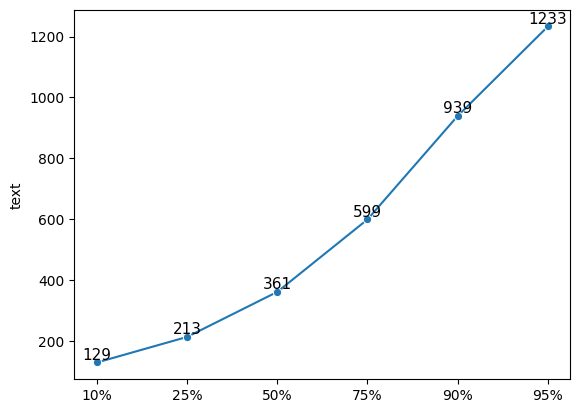

In [36]:
# 그래프 그리기
sns.lineplot(data=text_length[4:10], marker='o')

# 각 점에 숫자 표시
for i, v in enumerate(text_length[4:10]):
    plt.text(i, v, str(v), ha='center', va='bottom', fontsize=11)

plt.show()

# Cell Phones

In [37]:
df = pd.read_pickle('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Cell_Phones_v5_final.pkl')

print(df.shape)
df.head()

(23491, 17)


,user_id,asin,parent_asin,text,rating,title_y,roberta_emb,small_image_url,medium_image_url,large_image_url,VGG16_emb,user_bert_emb,item_bert_emb,user_roberta_emb,item_roberta_emb,LLaMA_Output,LLaVA_Output
0,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0BJKYJR3L,B0BJKYJR3L,"Nice privacy shield. Good color, fits well, et...",3,Jephuwneh 2 Pack Gradient Tempered Glass for i...,"[-0.0753104165, 0.1205661818, -0.0582872108, -...",https://m.media-amazon.com/images/I/515oPLx13k...,https://m.media-amazon.com/images/I/515oPLx13k...,https://m.media-amazon.com/images/I/515oPLx13k...,"[9.4065265656, 28.670337677, 22.95885849, 26.4...","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.3555999, -0.19625245, 0.338061, -0.1889423...","[-0.053886086, 0.1409396, -0.025606845, -0.112...","[-0.05482221, 0.11866534, -0.037660137, -0.100...","Based on this user review, it appears that the...",The image shows a cellphone with a screen prot...
1,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0BHTZQHQW,B0BHTZQHQW,"This thing is great. It's not too big, has a d...",5,"NEOCOR Magnetic Wireless Power Bank, 10,000mAh...","[-0.1076164767, 0.15895271300000002, -0.038697...",https://m.media-amazon.com/images/I/71K8BDxzsA...,https://m.media-amazon.com/images/I/71K8BDxzsA...,https://m.media-amazon.com/images/I/71K8BDxzsA...,"[15.0432891846, 40.8174591064, 0.0, 27.5127182...","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.5915019, -0.69345254, 0.21792011, -0.13003...","[-0.053886086, 0.1409396, -0.025606845, -0.112...","[-0.07991053, 0.16881612, -0.014415792, -0.127...","Based on the user review, here is a summary of...",The image shows a wireless power bank with a m...
2,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0B9N4VRB9,B0BHSSCXB2,This is a much better way to mount my iPhone (...,5,Lamicall Gooseneck Phone Holder Bed - [Newest ...,"[-0.098338306, 0.1566942036, -0.0378348567, -0...",https://m.media-amazon.com/images/I/71b+Sx-Jq7...,https://m.media-amazon.com/images/I/71b+Sx-Jq7...,https://m.media-amazon.com/images/I/71b+Sx-Jq7...,"[0.0, 57.4749221802, 14.7353601456, 36.8316497...","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.11259819, -0.25781307, 0.46874186, -0.3961...","[-0.053886086, 0.1409396, -0.025606845, -0.112...","[-0.085501574, 0.112952866, -0.022212008, -0.0...","Based on the user review, here is a summary of...",The image shows a cellphone holder with a flex...
3,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0B93H178F,B0B93H178F,"This is a fantastic charger, especially if you...",5,"Shargeek USB C Charger 140W Wall Charger, Mult...","[-0.0699621961, 0.1709383726, -0.0337884836, -...",https://m.media-amazon.com/images/I/61R6UXrAKT...,https://m.media-amazon.com/images/I/61R6UXrAKT...,https://m.media-amazon.com/images/I/61R6UXrAKT...,"[21.9141178131, 16.1274204254, 0.0, 10.3457145...","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.63115484, -0.17968105, 0.4211614, -0.10539...","[-0.053886086, 0.1409396, -0.025606845, -0.112...","[-0.05314668, 0.1396852, -0.016387641, -0.1113...","Based on the user review, here is a summary of...",The image shows a USB C charger with a power r...
4,AFERCDY2EFJKT7QUQ75GISNHTFOQ,B0BPXZWCBG,B0BPY47SY6,There never seems to be enough charging cords ...,4,"Charging Station for Multiple Devices,60W 12A ...","[-0.09403285380000001, 0.16169938450000002, -0...",https://m.media-amazon.com/images/I/51fqzioGKe...,https://m.media-amazon.com/images/I/51fqzioGKe...,https://m.media-amazon.com/images/I/51fqzioGKe...,"[0.0, 25.8072109222, 0.0, 35.9537582397, 0.0, ...","[-0.30125153, -0.10725977, 0.31016856, -0.1977...","[-0.442251, -0.18747163, 0.23647779, -0.066458...","[-0.06674541, 0.15736866, -0.014765534, -0.073...","[-0.08094199, 0.124280974, -0.008204151, -0.07...","Based on user reviews, it appears that users v...",The image shows a product packaging for a USB ...


In [40]:
# 데이터셋에서 글자 수 확인
text_length = df['text'].apply(lambda row : len(row)).describe(percentiles=[0.10, 0.25, 0.5, 0.75, 0.9, 0.95]).astype(int)

text_length

,text
count,23491
mean,647
std,616
min,8
10%,151
25%,262
50%,477
75%,830
90%,1314
95%,1729


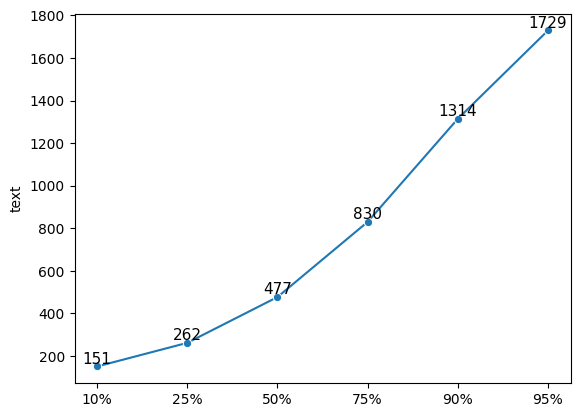

In [39]:
# 그래프 그리기
sns.lineplot(data=text_length[4:10], marker='o')

# 각 점에 숫자 표시
for i, v in enumerate(text_length[4:10]):
    plt.text(i, v, str(v), ha='center', va='bottom', fontsize=11)

plt.show()